[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/16-careers/notebooks/02-mock-interview-quiz.ipynb)

# 02 · Mock interview quiz runner

Practise with the module's **137-question interview bank** (model answers included) and **33 multiple-choice questions**, fully offline.

**What you will learn**
1. Load and explore the question bank with pandas.
2. Run a multiple-choice quiz (automatic marking).
3. Practise open questions and get a rough **self-check score** for your typed answer.
4. Build a balanced mock-interview set.
5. Schedule reviews with **spaced repetition** (Leitner boxes).

The notebook runs without typing (so it can be tested automatically). Set `INTERACTIVE = True` to answer with the keyboard. For a terminal version: `python code/quiz_runner.py mcq --n 10`.

## Step 0 — settings and the data loader

`INTERACTIVE = False` uses pre-written demo answers. Switch it to `True` when practising for real.

In [1]:
import pathlib, urllib.request

RAW = "https://raw.githubusercontent.com/vvvvvivekkk/AI-Engineer/main/16-careers/data/"

def data_path(name: str) -> pathlib.Path:
    """Find a data file locally (repo checkout) or download it (Colab)."""
    for p in [pathlib.Path("../data") / name, pathlib.Path("data") / name, pathlib.Path(name)]:
        if p.exists():
            return p
    target = pathlib.Path(name)
    urllib.request.urlretrieve(RAW + name, target)      # works in Colab once the repo is public
    return target
print("loader ready")

INTERACTIVE = False      # set True to type your own answers

loader ready


## Step 1 — load and explore the bank

Each row has a category, a level (junior / mid / senior), the question and a model answer. `value_counts` counts rows per category.

In [2]:
import pandas as pd
bank = pd.read_csv(data_path("question_bank.csv"))
mcq = pd.read_csv(data_path("mcq.csv"))
print(len(bank), "open questions,", len(mcq), "multiple-choice questions\n")
print(pd.crosstab(bank.category, bank.level))

137 open questions, 33 multiple-choice questions

level              junior  mid  senior
category                              
AI Trainer & Data       6    2       0
Agents                  4    6       2
Behavioural             7    5       0
Deep Learning           7    7       0
LLM System Design       0    5       5
LLMOps                  4    5       1
LLMs                    9   10       1
Machine Learning       11    8       0
Python                  8   10       0
RAG                     4    8       2


## Step 2 — a chart of the bank

Useful for planning: which areas have the most questions, and at which level.

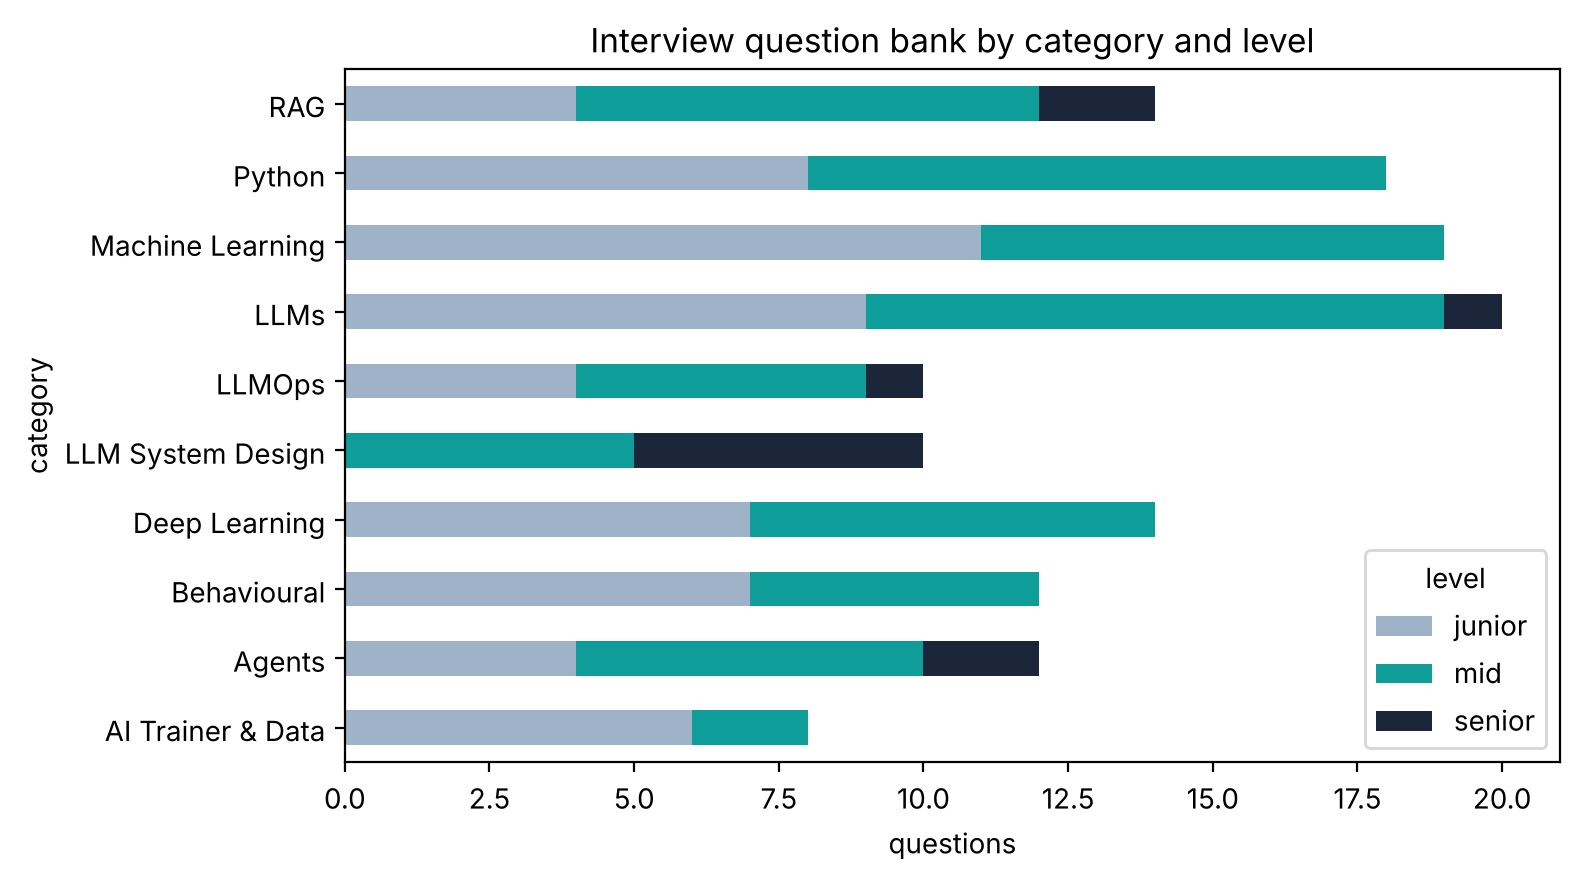

In [3]:
import matplotlib.pyplot as plt
pd.crosstab(bank.category, bank.level)[["junior", "mid", "senior"]].plot.barh(stacked=True, figsize=(8, 4.5),
                                                                             color=["#9fb3c8", "#0f9d9a", "#1b263b"])
plt.title("Interview question bank by category and level"); plt.xlabel("questions"); plt.tight_layout(); plt.show()

## Step 3 — the multiple-choice quiz

`run_mcq` shows each question and its options, takes an answer, marks it and explains. In demo mode the "answers" come from a list, so the run is repeatable. `random_state` makes the question sample the same every run.

In [4]:
def run_mcq(questions, answers=None):
    score = 0
    for i, (_, q) in enumerate(questions.iterrows()):
        print(f"Q{i+1} [{q.category}] {q.question}")
        for letter in "ABCD":
            print(f"    {letter}) {q[letter]}")
        ans = input("Answer A-D: ").strip().upper() if INTERACTIVE else answers[i]
        ok = ans == q.correct
        score += ok
        print(f"    you: {ans} -> {'correct' if ok else 'wrong, answer ' + q.correct}. {q.explanation}\n")
    print(f"Score {score}/{len(questions)}")
    return score

quiz = mcq.sample(5, random_state=3)
run_mcq(quiz, answers=list(quiz.correct.iloc[:3]) + ["A", "D"])   # demo: 3 right, then guesses

Q1 [Python] Which is best for thousands of concurrent network calls in one process?
    A) multiprocessing
    B) asyncio
    C) a for-loop
    D) recursion
    you: B -> correct. asyncio handles many I/O waits efficiently in a single thread.

Q2 [LLMs] LoRA trains...
    A) All weights
    B) Small added low-rank matrices
    C) Only the tokenizer
    D) Only embeddings
    you: B -> correct. The base model is frozen; small adapter matrices are trained.

Q3 [LLMs] For extracting fields into JSON, temperature should be...
    A) High
    B) Low
    C) Exactly 2
    D) Irrelevant
    you: B -> correct. Low temperature gives focused, repeatable outputs.

Q4 [Agents] In tool calling, who executes the tool?
    A) The LLM
    B) Your application code
    C) The user
    D) The vector DB
    you: A -> wrong, answer B. The model only requests a call; your code runs it and returns the result.

Q5 [AI Trainer & Data] A 'job' asks you to pay a registration fee first. This is...
    A) Normal
  

3

## Step 4 — open questions and a rough self-check score

Real interviews are open-ended. We compare your answer with the model answer by **keyword overlap**: the share of the model answer's content words (4+ letters, not stop words) that your answer contains. It is a *rough guide* — a good answer in different words can score low — so always read the model answer and judge the meaning yourself.

In [5]:
import re
STOP = set("a an the and or of to in on for is are be with by it its as that this from at can you your use used "
           "using into than then so not no do does how what why when which who more most also each their they them".split())

def keywords(text):
    return {w for w in re.findall(r"[a-z][a-z0-9-]{3,}", text.lower()) if w not in STOP}

def overlap(answer, model_answer):
    target = keywords(model_answer)
    return len(target & keywords(answer)) / len(target)

q = bank[bank.question.str.startswith("Precision vs recall")].iloc[0]
weak = "Precision and recall are metrics for models."
strong = ("Precision is the share of predicted positives that are really positive; recall is the share of real "
          "positives the model finds. For cancer screening recall matters most, for a spam filter precision. "
          "F1 balances both.")
print("Q:", q.question)
for label, ans in [("weak", weak), ("strong", strong)]:
    print(f"{label:6s} answer -> overlap {overlap(ans, q.model_answer):.0%}")
print("\nModel answer:", q.model_answer)

Q: Precision vs recall - explain with an example.
weak   answer -> overlap 7%
strong answer -> overlap 44%

Model answer: Precision: of everything the model flagged as positive, how much was really positive. Recall: of all real positives, how many the model found. For a cancer screening test, recall matters most (do not miss sick patients); for a spam filter, precision matters (do not hide real emails). F1 is their harmonic mean when you need a balance.


## Step 5 — a second opinion with TF-IDF

**TF-IDF cosine similarity** (see notebook 01) weighs rare, meaningful words more than common ones. Comparing two scorers shows that both rank the strong answer higher — and that neither is a real grader. In real practice, a friend, a mentor, or an LLM given the model answer as a rubric gives better feedback.

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

vec = TfidfVectorizer(stop_words="english").fit(bank.model_answer)    # learn word weights from the whole bank
def tfidf_sim(a, b):
    m = vec.transform([a, b])
    return cosine_similarity(m[0], m[1])[0, 0]

for label, ans in [("weak", weak), ("strong", strong)]:
    print(f"{label:6s} TF-IDF similarity {tfidf_sim(ans, q.model_answer):.2f}")

weak   TF-IDF similarity 0.27
strong TF-IDF similarity 0.71


## Step 6 — practise a few open questions

`practise` asks each question, collects an answer (typed, or from the demo list), and prints both scores plus the model answer. Use the feedback to rewrite your answer out loud.

In [7]:
def practise(questions, demo_answers=None):
    results = []
    for i, (_, q) in enumerate(questions.iterrows()):
        print(f"\nQ{i+1} [{q.category} / {q.level}] {q.question}")
        ans = input("> ") if INTERACTIVE else demo_answers[i]
        o, t = overlap(ans, q.model_answer), tfidf_sim(ans, q.model_answer)
        print(f"   your answer: {ans[:100]}")
        print(f"   overlap {o:.0%} | tf-idf {t:.2f}")
        print(f"   model answer: {q.model_answer[:220]}...")
        results.append({"question": q.question, "overlap": round(o, 2), "tfidf": round(t, 2)})
    return pd.DataFrame(results)

picked = bank[bank.category.isin(["RAG", "LLMOps"])].sample(3, random_state=1)
demo = ["You search documents first and give the chunks to the model so it can answer with citations.",
        "I don't know.",
        "Use percentiles because the average hides slow requests."]
practise(picked, demo)


Q1 [RAG / junior] What metadata would you store with each chunk?
   your answer: You search documents first and give the chunks to the model so it can answer with citations.
   overlap 3% | tf-idf 0.08
   model answer: Document ID and title, source URL or path, section heading, page number, created/updated date, author or owner, access permissions, language and chunk position. Metadata enables filtering (only this product, only recent ...

Q2 [LLMOps / mid] What is observability for LLM apps? Name a tool.
   your answer: I don't know.
   overlap 0% | tf-idf 0.00
   model answer: Recording enough detail about each request to understand behaviour later: a trace per request with spans for retrieval, model calls and tools, including prompts, outputs, tokens, cost, latency and user feedback. Tools in...

Q3 [RAG / junior] What is a vector database? Name some.
   your answer: Use percentiles because the average hides slow requests.
   overlap 0% | tf-idf 0.00
   model answer: A store optimi

,question,overlap,tfidf
0,What metadata would you store with each chunk?,0.03,0.08
1,What is observability for LLM apps? Name a tool.,0.00,0.00
2,What is a vector database? Name some.,0.00,0.00


## Step 7 — build a balanced mock interview

A real loop mixes areas. `mock_interview` picks questions per category in given proportions and prints a script a partner can read to you. `groupby(...).sample` draws from each group.

In [8]:
PLAN = {"Python": 2, "Machine Learning": 1, "LLMs": 2, "RAG": 2, "Agents": 1, "LLM System Design": 1, "Behavioural": 2}

def mock_interview(plan, level=None, seed=7):
    pool = bank if level is None else bank[bank.level.isin(level)]
    parts = [pool[pool.category == c].sample(min(n, (pool.category == c).sum()), random_state=seed)
             for c, n in plan.items()]
    return pd.concat(parts).reset_index(drop=True)

script = mock_interview(PLAN, level=["junior", "mid"])
for i, row in script.iterrows():
    print(f"{i+1:2d}. ({row.category}) {row.question}")
print(f"\n{len(script)} questions - allow about 4 minutes each, 45 minutes in total.")

 1. (Python) How do you write and run tests in Python?
 2. (Python) How would you read a 20 GB CSV file that does not fit in memory?
 3. (Machine Learning) Classification vs regression?
 4. (LLMs) What is a token, and why do tokens matter?
 5. (LLMs) What do temperature and top-p control?
 6. (RAG) Users say the RAG bot gives wrong answers. How do you debug it?
 7. (RAG) What is query rewriting?
 8. (Agents) How do you evaluate an agent?
 9. (LLM System Design) Design a customer-support chatbot over a company's help-centre articles.
10. (Behavioural) How do you prioritise when you have too much to do?
11. (Behavioural) Have you used AI tools to write code? How do you ensure quality?

11 questions - allow about 4 minutes each, 45 minutes in total.


## Step 8 — spaced repetition with Leitner boxes

**Spaced repetition** means reviewing a question just before you would forget it. The **Leitner system** uses boxes: every question starts in box 1 (review tomorrow). Answer well → move up a box (wait longer); answer badly → back to box 1. Below, we simulate two weeks of practice with made-up self-scores.

In [9]:
import random, datetime
random.seed(0)
INTERVAL = {1: 1, 2: 3, 3: 7, 4: 14}          # box -> days until next review
start = datetime.date(2026, 12, 1)
cards = {q: {"box": 1, "due": start} for q in bank.question.sample(8, random_state=2)}

for day in range(14):
    today = start + datetime.timedelta(days=day)
    due = [q for q, c in cards.items() if c["due"] <= today]
    for qq in due:
        good = random.random() < 0.65 + 0.08 * cards[qq]["box"]     # easier the more you have practised
        cards[qq]["box"] = min(4, cards[qq]["box"] + 1) if good else 1
        cards[qq]["due"] = today + datetime.timedelta(days=INTERVAL[cards[qq]["box"]])

schedule = pd.DataFrame([{"question": q[:55], "box": c["box"], "next review": c["due"]} for q, c in cards.items()])
schedule.sort_values("next review")

,question,box,next review
2,"When would you use prompting, RAG or fine-tuning?",2,2026-12-15
6,What is gradient boosting and how is it differ...,2,2026-12-15
0,What would you monitor for an LLM app in produ...,3,2026-12-16
1,What is Docker and why is it useful?,3,2026-12-16
7,What is observability for LLM apps? Name a tool.,3,2026-12-16
3,What is a virtual environment and why use one?,4,2026-12-25
4,How does a convolutional neural network (CNN) ...,4,2026-12-25
5,What do *args and **kwargs mean?,4,2026-12-25


## Recap

- The bank has 137 open questions (with model answers) and 33 MCQs; filter by category and level.
- Automatic scores (keyword overlap, TF-IDF) are rough self-checks, not grades — read the model answer.
- Mix areas in mock interviews and practise aloud, ideally with a partner reading the script.
- Spaced repetition (Leitner boxes) puts your time on the questions you keep missing.

**Try it yourself:** set `INTERACTIVE = True`, run Step 6 with five questions from your weakest category, then rewrite your two lowest-scoring answers and try again.